<a href="https://colab.research.google.com/github/shruti18sk/face-recognition-project/blob/main/face_reccognition_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install face_recognition -q

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


/usr/local/lib/python3.13/dist-packages/face_recognition_models/__init__.py:7: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


Total images: 1288
People in dataset:
  Ariel_Sharon: 77 photos
  Colin_Powell: 236 photos
  Donald_Rumsfeld: 121 photos
  George_W_Bush: 530 photos
  Gerhard_Schroeder: 109 photos
  Hugo_Chavez: 71 photos
  Tony_Blair: 144 photos


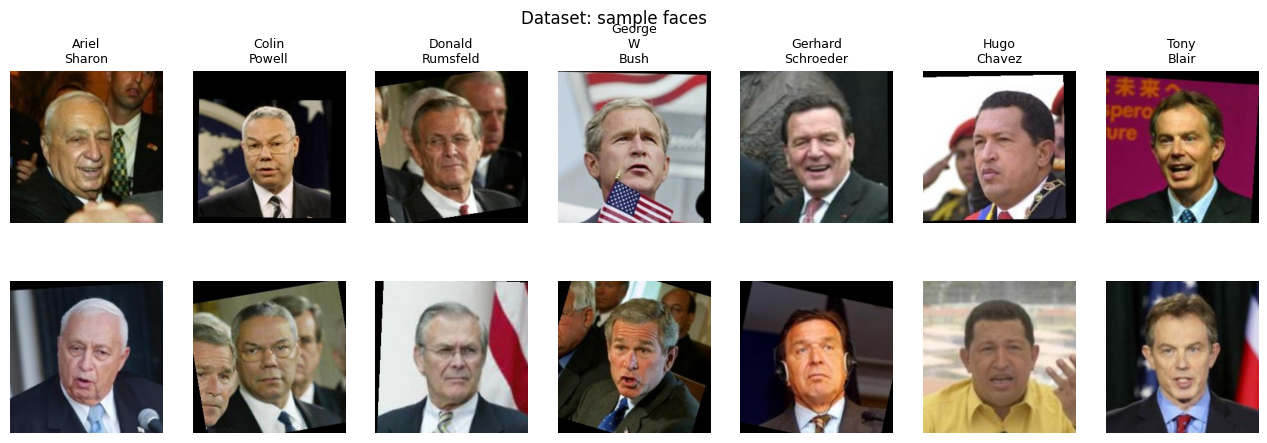

In [ ]:
import os
import shutil
import cv2
import numpy as np
import matplotlib.pyplot as plt
import face_recognition
from sklearn.datasets import fetch_lfw_people

data = fetch_lfw_people(min_faces_per_person=70, slice_=None, resize=1.0, color=True)
images, labels = data.images, data.target
names = [str(n).replace(" ", "_") for n in data.target_names]

if images.max() <= 1.0:
    images = images * 255
images = images.astype(np.uint8)

print("Total images:", len(images))
print("People in dataset:")
for i, n in enumerate(names):
    print(f"  {n}: {(labels == i).sum()} photos")

# 2 sample photos per person
fig, axes = plt.subplots(2, len(names), figsize=(2.3 * len(names), 5))
for pid in range(len(names)):
    idxs = np.where(labels == pid)[0][:2]
    for r, i in enumerate(idxs):
        axes[r, pid].imshow(images[i])
        axes[r, pid].axis("off")
    axes[0, pid].set_title(names[pid].replace("_", "\n"), fontsize=9)
plt.suptitle("Dataset: sample faces")
plt.show()

Known people (Q): ['Ariel_Sharon', 'Colin_Powell', 'Donald_Rumsfeld', 'George_W_Bush', 'Gerhard_Schroeder']
Unknown people (only in K): ['Hugo_Chavez', 'Tony_Blair']
Q: 5 photos | K: 140 photos


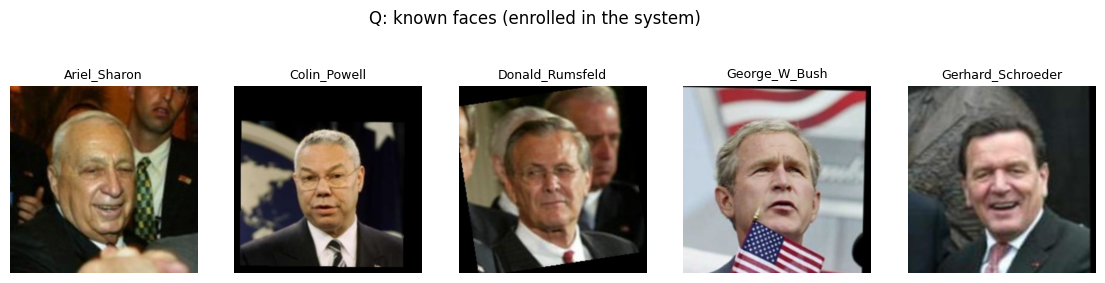

In [ ]:
# Delete old folders so no stale files remain
shutil.rmtree("Q", ignore_errors=True)
shutil.rmtree("K", ignore_errors=True)
os.makedirs("Q")
os.makedirs("K")

known_ids = list(range(5))                                          # 5 people go into Q
unknown_ids = [i for i in range(len(names)) if i not in known_ids]  # the rest are unknown

def save(img, path):
    cv2.imwrite(path, cv2.cvtColor(img, cv2.COLOR_RGB2BGR))

def read_img(path):
    img = cv2.imread(path)
    if img is None:
        return None
    (h, w) = img.shape[:2]
    width = 500
    ratio = width / float(w)
    height = int(h * ratio)
    return cv2.resize(img, (width, height))

# Q: 1 photo per known person (with a detectable face)
used = set()
for pid in known_ids:
    for i in np.where(labels == pid)[0]:
        if face_recognition.face_encodings(images[i]):
            save(images[i], f"Q/{names[pid]}.png")
            used.add(i)
            break

# K: 20 different photos per person (5 known + 2 unknown), excluding the Q photo
rng = np.random.default_rng(42)
for pid in known_ids + unknown_ids:
    idxs = [i for i in np.where(labels == pid)[0] if i not in used]
    chosen = rng.choice(idxs, size=20, replace=False)
    for n, i in enumerate(chosen, 1):
        save(images[i], f"K/{names[pid]}_{n:02d}.png")

K_files = sorted(os.listdir("K"))

print("Known people (Q):", [f[:-4] for f in sorted(os.listdir("Q"))])
print("Unknown people (only in K):", [names[i] for i in unknown_ids])
print("Q:", len(os.listdir("Q")), "photos | K:", len(K_files), "photos")

# Show the known faces
fig, axes = plt.subplots(1, 5, figsize=(14, 3.5))
for ax, f in zip(axes, sorted(os.listdir("Q"))):
    ax.imshow(cv2.cvtColor(read_img("Q/" + f), cv2.COLOR_BGR2RGB))
    ax.set_title(f[:-4], fontsize=9)
    ax.axis("off")
plt.suptitle("Q: known faces (enrolled in the system)")
plt.show()

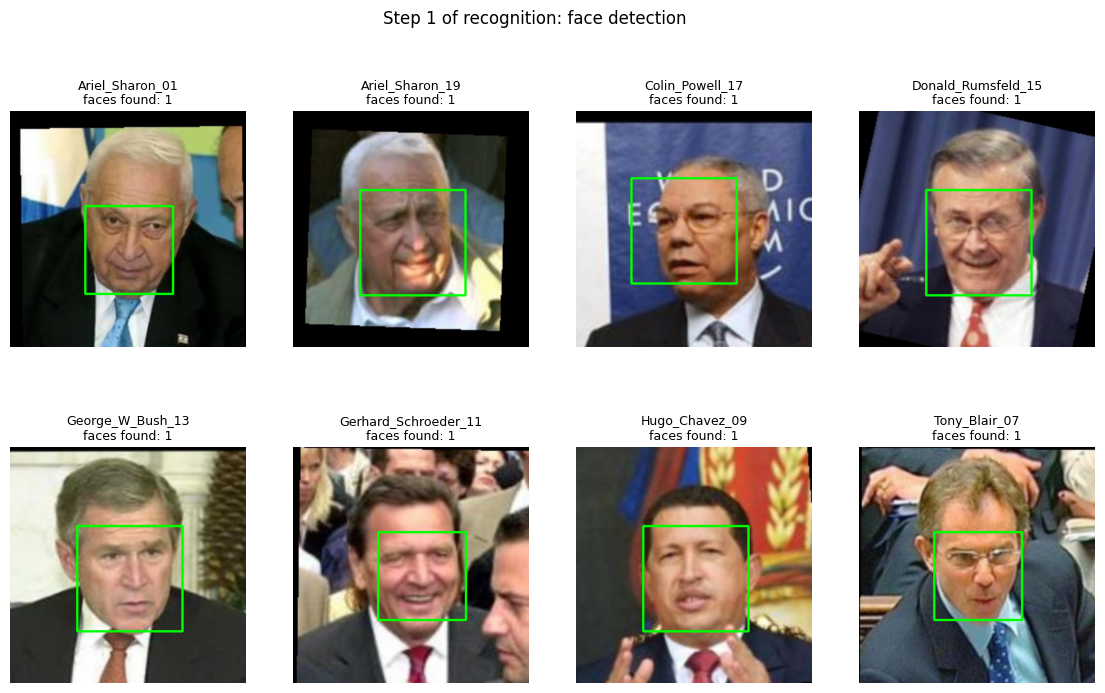

Face detected in 140 of 140 test photos


In [ ]:
# Face detection on 8 test photos
sample_files = K_files[::18][:8]

fig, axes = plt.subplots(2, 4, figsize=(14, 8))
for ax, f in zip(axes.ravel(), sample_files):
    img = read_img("K/" + f)
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    locs = face_recognition.face_locations(rgb)
    for (top, right, bottom, left) in locs:
        cv2.rectangle(rgb, (left, top), (right, bottom), (0, 255, 0), 3)
    ax.imshow(rgb)
    ax.set_title(f"{f[:-4]}\nfaces found: {len(locs)}", fontsize=9)
    ax.axis("off")
plt.suptitle("Step 1 of recognition: face detection")
plt.show()

# Count how many test photos have a detected face
found = 0
for f in K_files:
    rgb = cv2.cvtColor(read_img("K/" + f), cv2.COLOR_BGR2RGB)
    if face_recognition.face_locations(rgb):
        found += 1
print(f"Face detected in {found} of {len(K_files)} test photos")

Embedding shape: (128,) -> one face = 128 numbers
First 10 numbers: [-0.009  0.051  0.007  0.035 -0.009 -0.025  0.076 -0.142  0.113 -0.016]


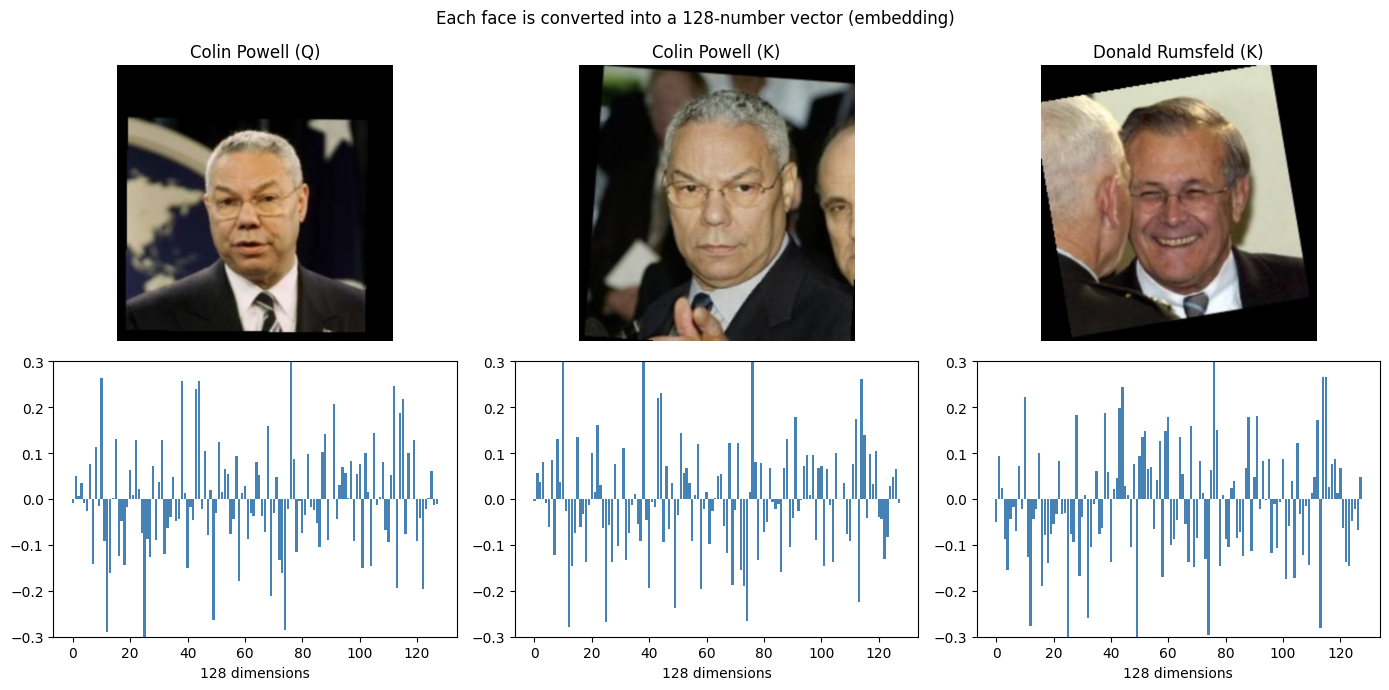


Distance (Colin Powell vs Colin Powell)   : 0.403  <- small = same person
Distance (Colin Powell vs Donald Rumsfeld): 0.772  <- large = different person
A distance below 0.6 means a match


In [ ]:
def get_embedding(path):
    img = read_img(path)
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    encs = face_recognition.face_encodings(rgb)
    return encs[0] if encs else None

# Three photos: Q Colin Powell, K Colin Powell, K Donald Rumsfeld
p1 = "Q/Colin_Powell.png"
p2 = "K/Colin_Powell_01.png"
p3 = "K/Donald_Rumsfeld_01.png"

e1, e2, e3 = get_embedding(p1), get_embedding(p2), get_embedding(p3)

print("Embedding shape:", e1.shape, "-> one face = 128 numbers")
print("First 10 numbers:", np.round(e1[:10], 3))

# The three photos and their embeddings
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for col, (p, e, t) in enumerate([(p1, e1, "Colin Powell (Q)"),
                                  (p2, e2, "Colin Powell (K)"),
                                  (p3, e3, "Donald Rumsfeld (K)")]):
    axes[0, col].imshow(cv2.cvtColor(read_img(p), cv2.COLOR_BGR2RGB))
    axes[0, col].set_title(t)
    axes[0, col].axis("off")
    axes[1, col].bar(range(128), e, color="steelblue")
    axes[1, col].set_ylim(-0.3, 0.3)
    axes[1, col].set_xlabel("128 dimensions")
plt.suptitle("Each face is converted into a 128-number vector (embedding)")
plt.tight_layout()
plt.show()

# Distance: same person vs different person
d_same = np.linalg.norm(e1 - e2)
d_diff = np.linalg.norm(e1 - e3)
print(f"\nDistance (Colin Powell vs Colin Powell)   : {d_same:.3f}  <- small = same person")
print(f"Distance (Colin Powell vs Donald Rumsfeld): {d_diff:.3f}  <- large = different person")
print("A distance below 0.6 means a match")

In [ ]:
# Embeddings of Q (known)
Q_encodings, Q_names = [], []
for f in sorted(os.listdir("Q")):
    e = get_embedding("Q/" + f)
    if e is not None:
        Q_encodings.append(e)
        Q_names.append(f[:-4])

# Embeddings of K (test)
K_encodings, K_person, K_actual, K_names_ok = [], [], [], []
for f in K_files:
    e = get_embedding("K/" + f)
    if e is None:
        print("No face found:", f)
        continue
    person = f.rsplit("_", 1)[0]
    K_encodings.append(e)
    K_person.append(person)                                        # actual name
    K_actual.append(person if person in Q_names else "unknown")    # known or unknown
    K_names_ok.append(f)

Q_encodings = np.array(Q_encodings)
K_encodings = np.array(K_encodings)
K_person_arr = np.array(K_person)

print("Q embeddings shape:", Q_encodings.shape)
print("K embeddings shape:", K_encodings.shape)
print("Known:", Q_names)
print("Unknown test photos:", K_actual.count("unknown"), "| known:", len(K_actual) - K_actual.count("unknown"))

Q embeddings shape: (5, 128)
K embeddings shape: (140, 128)
Known: ['Ariel_Sharon', 'Colin_Powell', 'Donald_Rumsfeld', 'George_W_Bush', 'Gerhard_Schroeder']
Unknown test photos: 40 | known: 100


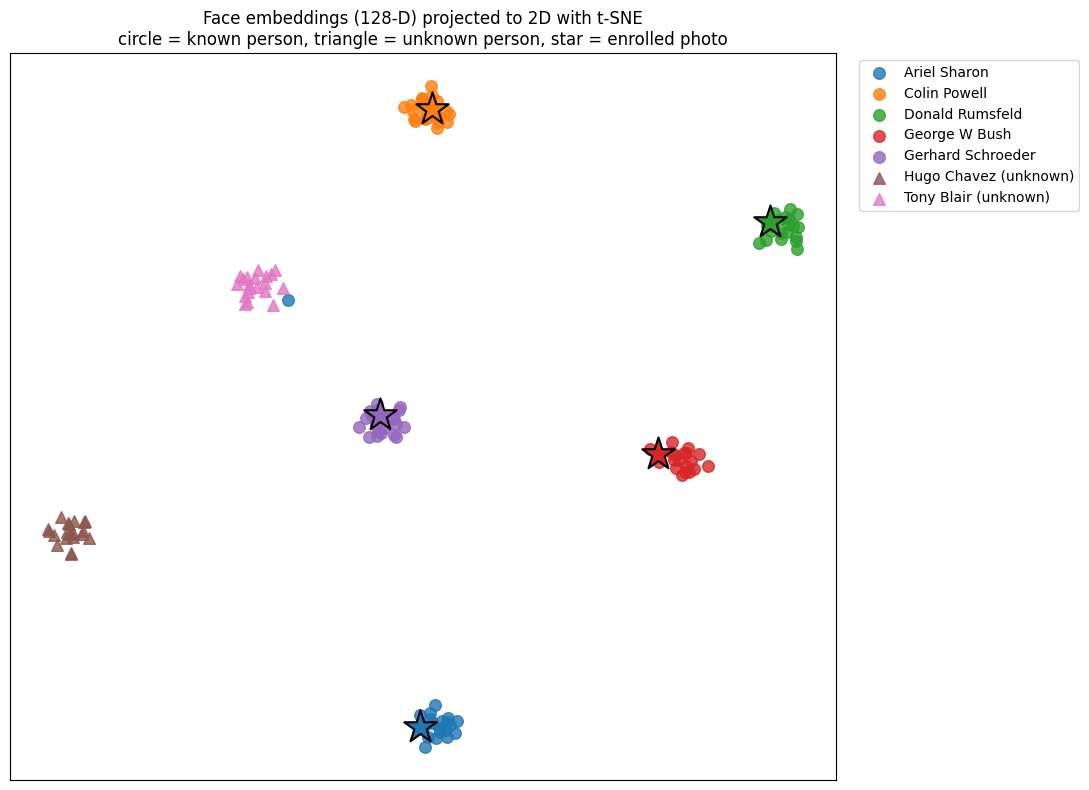

In [ ]:
from sklearn.manifold import TSNE

# Reduce 128 dimensions to 2D so we can see them
all_enc = np.vstack([K_encodings, Q_encodings])
tsne = TSNE(n_components=2, perplexity=15, init="pca", random_state=42)
pts = tsne.fit_transform(all_enc)
K_pts, Q_pts = pts[:len(K_encodings)], pts[len(K_encodings):]

people = sorted(set(K_person))
colors = plt.cm.tab10(np.arange(len(people)))

plt.figure(figsize=(11, 8))
for c, p in zip(colors, people):
    m = K_person_arr == p
    is_known = p in Q_names
    plt.scatter(K_pts[m, 0], K_pts[m, 1], color=c, s=70, alpha=0.8,
                marker="o" if is_known else "^",
                label=p.replace("_", " ") + ("" if is_known else " (unknown)"))

# Enrolled photos as stars
for (x, y), n in zip(Q_pts, Q_names):
    plt.scatter(x, y, color=colors[people.index(n)], marker="*", s=600,
                edgecolor="black", linewidth=1.5, zorder=5)

plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.title("Face embeddings (128-D) projected to 2D with t-SNE\n"
          "circle = known person, triangle = unknown person, star = enrolled photo")
plt.xticks([]); plt.yticks([])
plt.tight_layout()
plt.show()

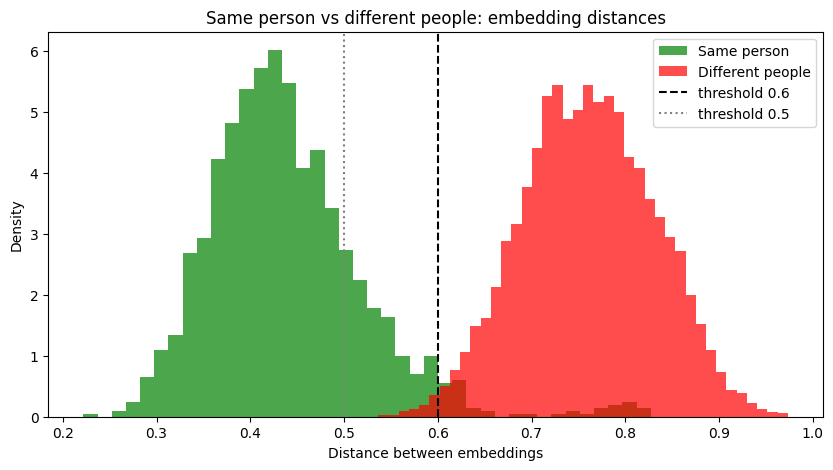

Same person pairs      : 1330 | average distance: 0.439
Different people pairs : 8400 | average distance: 0.761
Same-person pairs above 0.6 (would be rejected): 3.7%
Different-people pairs below 0.6 (would be wrongly matched): 0.8%


In [ ]:
# Distance between all pairs of test photos
n = len(K_encodings)
diff = K_encodings[:, None, :] - K_encodings[None, :, :]
dist_matrix = np.linalg.norm(diff, axis=2)

iu = np.triu_indices(n, k=1)                       # each pair only once
pair_d = dist_matrix[iu]
same = (K_person_arr[iu[0]] == K_person_arr[iu[1]])

d_same_all = pair_d[same]
d_diff_all = pair_d[~same]

plt.figure(figsize=(10, 5))
plt.hist(d_same_all, bins=40, alpha=0.7, color="green", label="Same person", density=True)
plt.hist(d_diff_all, bins=40, alpha=0.7, color="red", label="Different people", density=True)
plt.axvline(0.6, color="black", linestyle="--", label="threshold 0.6")
plt.axvline(0.5, color="gray", linestyle=":", label="threshold 0.5")
plt.xlabel("Distance between embeddings")
plt.ylabel("Density")
plt.title("Same person vs different people: embedding distances")
plt.legend()
plt.show()

print(f"Same person pairs      : {len(d_same_all)} | average distance: {d_same_all.mean():.3f}")
print(f"Different people pairs : {len(d_diff_all)} | average distance: {d_diff_all.mean():.3f}")
print(f"Same-person pairs above 0.6 (would be rejected): {(d_same_all > 0.6).mean()*100:.1f}%")
print(f"Different-people pairs below 0.6 (would be wrongly matched): {(d_diff_all < 0.6).mean()*100:.1f}%")

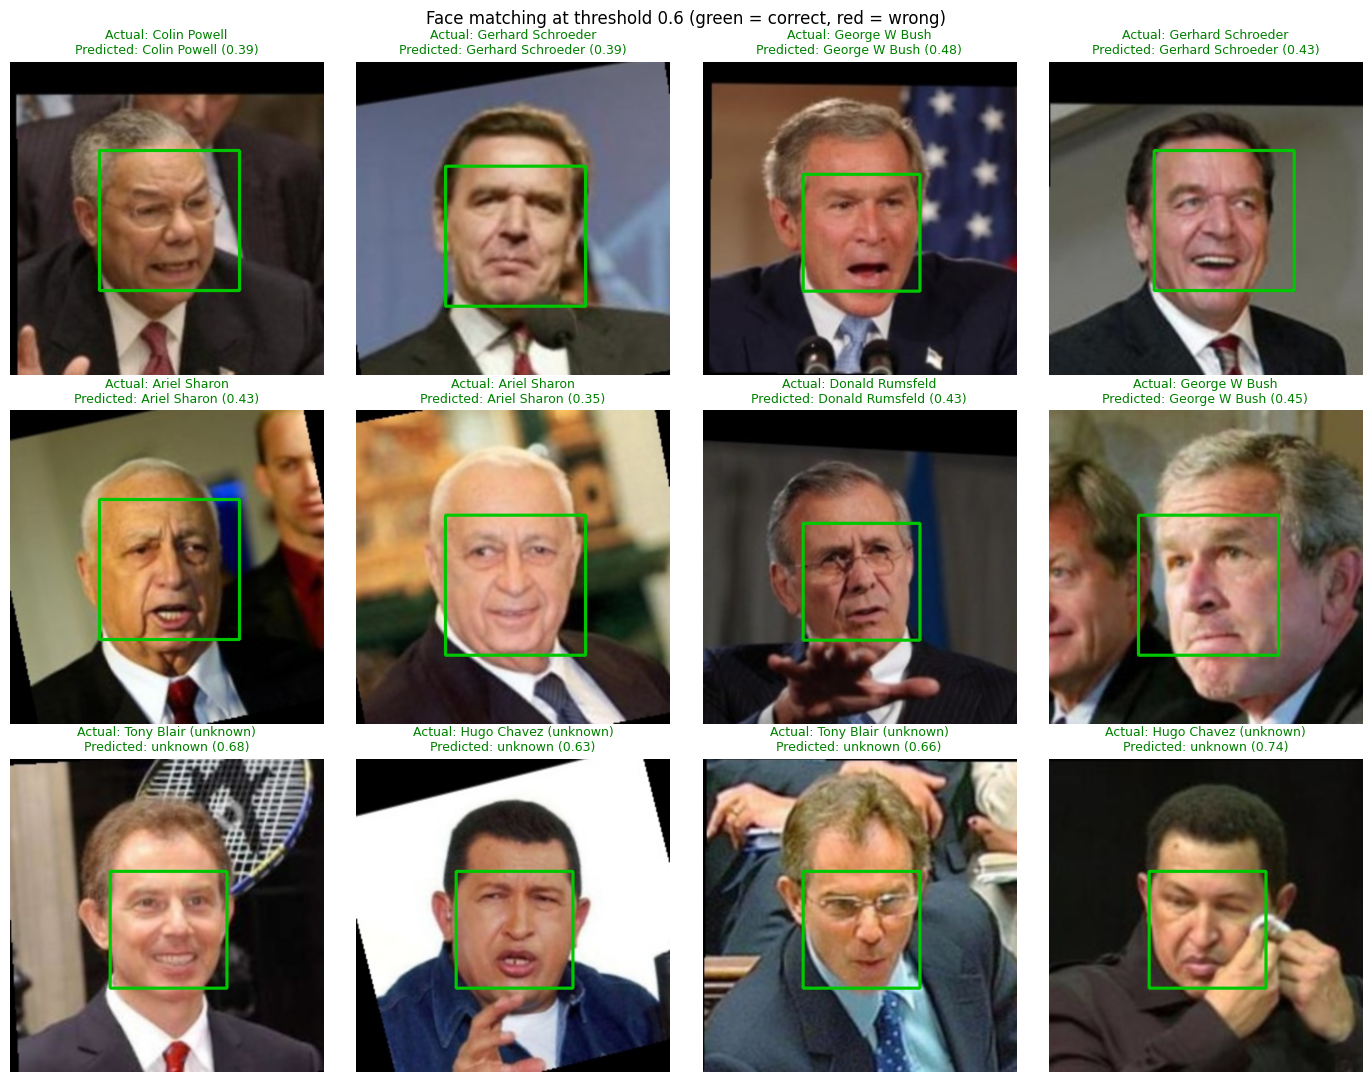

In [ ]:
def predict(th):
    d = np.linalg.norm(K_encodings[:, None, :] - Q_encodings[None, :, :], axis=2)
    best = d.argmin(axis=1)
    best_d = d.min(axis=1)
    pred = np.array([Q_names[b] if bd <= th else "unknown" for b, bd in zip(best, best_d)])
    return pred, best_d

TH = 0.6
pred, best_d = predict(TH)
actual = np.array(K_actual)

# 12 photos: 8 known people + 4 unknown people
rng = np.random.default_rng(3)
known_idx = np.where(actual != "unknown")[0]
unk_idx = np.where(actual == "unknown")[0]
pick = list(rng.choice(known_idx, 8, replace=False)) + list(rng.choice(unk_idx, 4, replace=False))

fig, axes = plt.subplots(3, 4, figsize=(14, 11))
for ax, i in zip(axes.ravel(), pick):
    img = read_img("K/" + K_names_ok[i])
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    locs = face_recognition.face_locations(rgb)
    ok = pred[i] == actual[i]
    if locs:
        top, right, bottom, left = locs[0]
        cv2.rectangle(rgb, (left, top), (right, bottom), (0, 200, 0) if ok else (220, 0, 0), 3)
    real = K_person[i].replace("_", " ") + (" (unknown)" if actual[i] == "unknown" else "")
    ax.imshow(rgb)
    ax.set_title(f"Actual: {real}\nPredicted: {pred[i].replace('_', ' ')} ({best_d[i]:.2f})",
                 fontsize=9, color="green" if ok else "red")
    ax.axis("off")

plt.suptitle(f"Face matching at threshold {TH} (green = correct, red = wrong)")
plt.tight_layout()
plt.savefig("results.png", dpi=150)
plt.show()


===== Threshold 0.6 =====
Test images   : 140
Accuracy      : 138/140 = 98.6%
False accepts : 1
False rejects : 1
Wrong person  : 0
No face found : 0

===== Threshold 0.5 =====
Test images   : 140
Accuracy      : 134/140 = 95.7%
False accepts : 0
False rejects : 6
Wrong person  : 0
No face found : 0


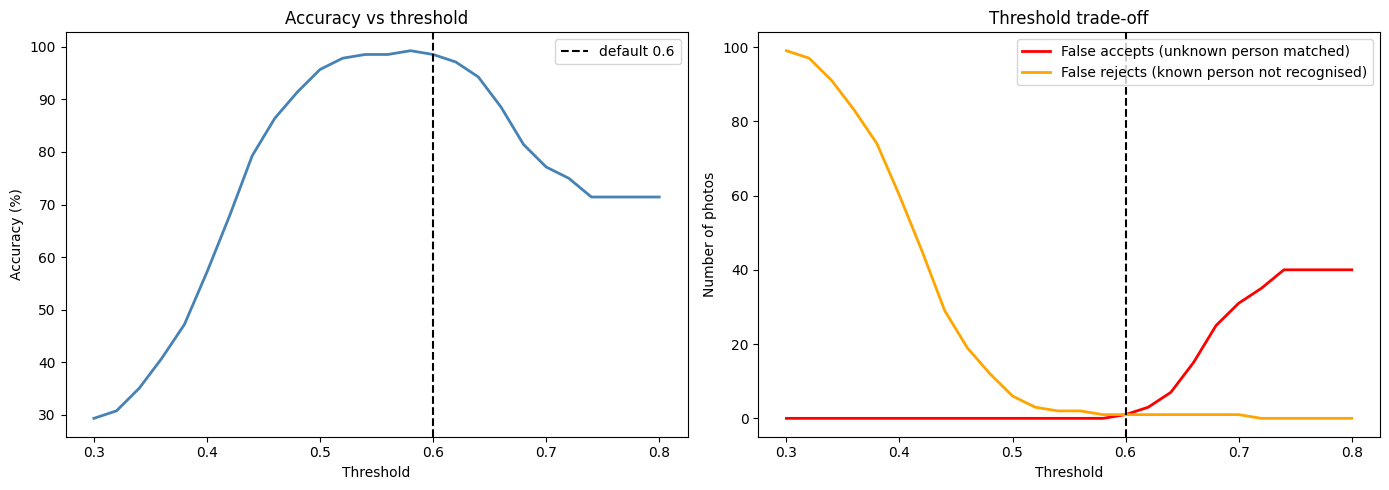

In [ ]:
N_TOTAL = len(K_files)   # 140 (photos without a detected face are also counted)

def report(th):
    p, _ = predict(th)
    correct = (p == actual).sum()
    fa = ((p != "unknown") & (actual == "unknown")).sum()                          # unknown person was matched
    fr = ((p == "unknown") & (actual != "unknown")).sum()                          # known person was not recognised
    wp = ((p != "unknown") & (actual != "unknown") & (p != actual)).sum()          # known person labelled as another known person
    nf = N_TOTAL - len(actual)                                                     # no face detected
    print(f"\n===== Threshold {th} =====")
    print(f"Test images   : {N_TOTAL}")
    print(f"Accuracy      : {correct}/{N_TOTAL} = {correct / N_TOTAL * 100:.1f}%")
    print(f"False accepts : {fa}")
    print(f"False rejects : {fr}")
    print(f"Wrong person  : {wp}")
    print(f"No face found : {nf}")

report(0.6)
report(0.5)

# What changes when the threshold changes
ths = np.arange(0.30, 0.81, 0.02)
acc, fa_l, fr_l = [], [], []
for th in ths:
    p, _ = predict(th)
    acc.append((p == actual).mean() * 100)
    fa_l.append(((p != "unknown") & (actual == "unknown")).sum())
    fr_l.append(((p == "unknown") & (actual != "unknown")).sum())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(ths, acc, color="steelblue", linewidth=2)
axes[0].axvline(0.6, color="black", linestyle="--", label="default 0.6")
axes[0].set_xlabel("Threshold")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_title("Accuracy vs threshold")
axes[0].legend()

axes[1].plot(ths, fa_l, color="red", linewidth=2, label="False accepts (unknown person matched)")
axes[1].plot(ths, fr_l, color="orange", linewidth=2, label="False rejects (known person not recognised)")
axes[1].axvline(0.6, color="black", linestyle="--")
axes[1].set_xlabel("Threshold")
axes[1].set_ylabel("Number of photos")
axes[1].set_title("Threshold trade-off")
axes[1].legend()

plt.tight_layout()
plt.show()

2 mistakes at threshold 0.6


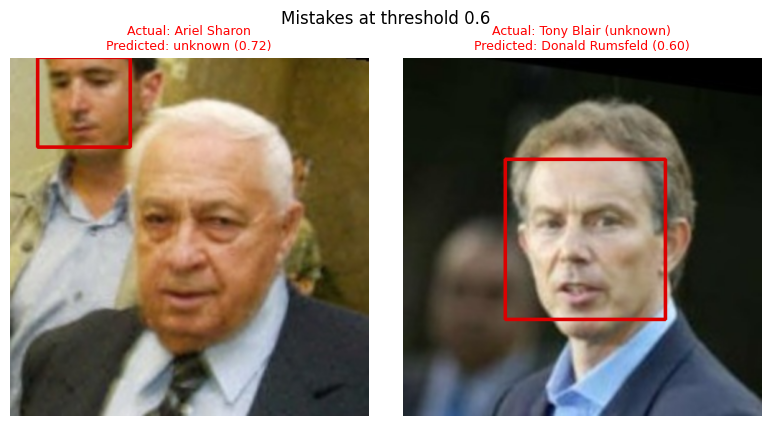

In [ ]:
pred, best_d = predict(0.6)
wrong = np.where(pred != actual)[0]
print(len(wrong), "mistakes at threshold 0.6")

if len(wrong) > 0:
    cols = min(4, len(wrong))
    rows = (len(wrong) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4.3 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, i in zip(axes.ravel(), wrong):
        img = read_img("K/" + K_names_ok[i])
        rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        locs = face_recognition.face_locations(rgb)
        if locs:
            top, right, bottom, left = locs[0]
            cv2.rectangle(rgb, (left, top), (right, bottom), (220, 0, 0), 3)
        real = K_person[i].replace("_", " ") + (" (unknown)" if actual[i] == "unknown" else "")
        ax.imshow(rgb)
        ax.set_title(f"Actual: {real}\nPredicted: {pred[i].replace('_', ' ')} ({best_d[i]:.2f})",
                     fontsize=9, color="red")
    plt.suptitle("Mistakes at threshold 0.6")
    plt.tight_layout()
    plt.show()

In [14]:
def largest_box(rgb):
    # Return the largest detected face (by box area), or None
    locs = face_recognition.face_locations(rgb)
    if not locs:
        return None
    areas = [(b - t) * (r - l) for (t, r, b, l) in locs]
    return locs[int(np.argmax(areas))]

def get_embedding_largest(path):
    rgb = cv2.cvtColor(read_img(path), cv2.COLOR_BGR2RGB)
    box = largest_box(rgb)
    if box is None:
        return None
    return face_recognition.face_encodings(rgb, [box])[0]

# Embeddings of Q (known), using the largest face
Q_encodings, Q_names = [], []
for f in sorted(os.listdir("Q")):
    e = get_embedding_largest("Q/" + f)
    if e is not None:
        Q_encodings.append(e)
        Q_names.append(f[:-4])

# Embeddings of K (test), using the largest face
K_encodings, K_person, K_actual, K_names_ok = [], [], [], []
for f in K_files:
    e = get_embedding_largest("K/" + f)
    if e is None:
        print("No face found:", f)
        continue
    person = f.rsplit("_", 1)[0]
    K_encodings.append(e)
    K_person.append(person)
    K_actual.append(person if person in Q_names else "unknown")
    K_names_ok.append(f)

Q_encodings = np.array(Q_encodings)
K_encodings = np.array(K_encodings)
K_person_arr = np.array(K_person)
actual = np.array(K_actual)
N_TOTAL = len(K_files)

def predict(th):
    d = np.linalg.norm(K_encodings[:, None, :] - Q_encodings[None, :, :], axis=2)
    best = d.argmin(axis=1)
    best_d = d.min(axis=1)
    pred = np.array([Q_names[b] if bd <= th else "unknown" for b, bd in zip(best, best_d)])
    return pred, best_d

def report(th):
    p, _ = predict(th)
    correct = (p == actual).sum()
    fa = ((p != "unknown") & (actual == "unknown")).sum()
    fr = ((p == "unknown") & (actual != "unknown")).sum()
    wp = ((p != "unknown") & (actual != "unknown") & (p != actual)).sum()
    nf = N_TOTAL - len(actual)
    print(f"\n===== Threshold {th} (largest face) =====")
    print(f"Test images   : {N_TOTAL}")
    print(f"Accuracy      : {correct}/{N_TOTAL} = {correct / N_TOTAL * 100:.1f}%")
    print(f"False accepts : {fa}")
    print(f"False rejects : {fr}")
    print(f"Wrong person  : {wp}")
    print(f"No face found : {nf}")

report(0.6)
report(0.5)


===== Threshold 0.6 (largest face) =====
Test images   : 140
Accuracy      : 139/140 = 99.3%
False accepts : 1
False rejects : 0
Wrong person  : 0
No face found : 0

===== Threshold 0.5 (largest face) =====
Test images   : 140
Accuracy      : 135/140 = 96.4%
False accepts : 0
False rejects : 5
Wrong person  : 0
No face found : 0


Photos with more than one face: 7 of 140
1 mistakes at threshold 0.6


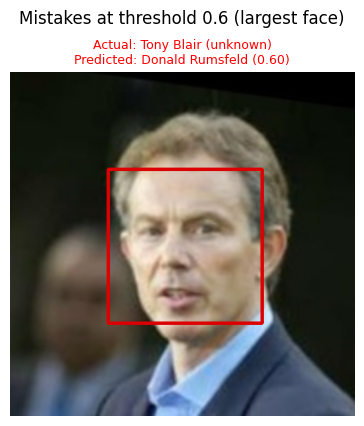

In [15]:
# How many test photos contain more than one detected face?
multi = []
for f in K_files:
    rgb = cv2.cvtColor(read_img("K/" + f), cv2.COLOR_BGR2RGB)
    n_faces = len(face_recognition.face_locations(rgb))
    if n_faces > 1:
        multi.append((f, n_faces))
print(f"Photos with more than one face: {len(multi)} of {len(K_files)}")

# Mistakes at threshold 0.6 (the largest face is boxed)
pred, best_d = predict(0.6)
wrong = np.where(pred != actual)[0]
print(len(wrong), "mistakes at threshold 0.6")

if len(wrong) > 0:
    cols = min(4, len(wrong))
    rows = (len(wrong) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4.3 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, i in zip(axes.ravel(), wrong):
        rgb = cv2.cvtColor(read_img("K/" + K_names_ok[i]), cv2.COLOR_BGR2RGB)
        box = largest_box(rgb)
        if box:
            top, right, bottom, left = box
            cv2.rectangle(rgb, (left, top), (right, bottom), (220, 0, 0), 3)
        real = K_person[i].replace("_", " ") + (" (unknown)" if actual[i] == "unknown" else "")
        ax.imshow(rgb)
        ax.set_title(f"Actual: {real}\nPredicted: {pred[i].replace('_', ' ')} ({best_d[i]:.2f})",
                     fontsize=9, color="red")
    plt.suptitle("Mistakes at threshold 0.6 (largest face)")
    plt.tight_layout()
    plt.show()

In [16]:
# Larger dataset
from tqdm.auto import tqdm
from sklearn.datasets import fetch_lfw_people

# Larger LFW subset: every person with at least 20 photos
big = fetch_lfw_people(min_faces_per_person=20, slice_=None, resize=1.0, color=True)
labels_b = big.target
names_b = [str(n).replace(" ", "_") for n in big.target_names]
scale255 = big.images[:50].max() <= 1.0
print("People in the larger dataset:", len(names_b), "| images:", len(labels_b))

def get_rgb(i):
    a = big.images[i]
    if scale255:
        a = a * 255
    return a.astype(np.uint8)

def embed_rgb(rgb):
    # Resize like before, detect faces, and embed the largest one
    rgb = cv2.resize(rgb, (500, 500))
    locs = face_recognition.face_locations(rgb)
    if not locs:
        return None
    areas = [(b - t) * (r - l) for (t, r, b, l) in locs]
    box = locs[int(np.argmax(areas))]
    return face_recognition.face_encodings(rgb, [box])[0]

rng = np.random.default_rng(42)
N_KNOWN = 30     # people enrolled with 1 photo each
N_TEST = 10      # test photos per person

order = rng.permutation(len(names_b))
known_b = [int(p) for p in order[:N_KNOWN]]
unknown_b = [int(p) for p in order[N_KNOWN:]]
print("Known (enrolled):", len(known_b), "| Unknown (never enrolled):", len(unknown_b))

# Enroll: 1 photo per known person
Qb_enc, Qb_names, used_b = [], [], set()
for pid in tqdm(known_b, desc="Enrolling"):
    for i in rng.permutation(np.where(labels_b == pid)[0]):
        e = embed_rgb(get_rgb(i))
        if e is not None:
            Qb_enc.append(e)
            Qb_names.append(names_b[pid])
            used_b.add(int(i))
            break

# Test photos: N_TEST per person (the enrolled photo is excluded)
Kb_enc, Kb_actual = [], []
no_face_b = 0
for pid in tqdm(known_b + unknown_b, desc="Testing"):
    cand = [i for i in rng.permutation(np.where(labels_b == pid)[0]) if int(i) not in used_b][:N_TEST]
    for i in cand:
        e = embed_rgb(get_rgb(i))
        if e is None:
            no_face_b += 1
            continue
        Kb_enc.append(e)
        Kb_actual.append(names_b[pid] if names_b[pid] in Qb_names else "unknown")

del big   # free memory
print("\nEnrolled:", len(Qb_enc), "| Test embeddings:", len(Kb_enc), "| No face found:", no_face_b)

People in the larger dataset: 62 | images: 3023
Known (enrolled): 30 | Unknown (never enrolled): 32


Enrolling:   0%|          | 0/30 [00:00<?, ?it/s]

Testing:   0%|          | 0/62 [00:00<?, ?it/s]


Enrolled: 30 | Test embeddings: 620 | No face found: 0



===== Larger test, threshold 0.6 =====
Enrolled people : 30
Test images     : 620 (300 of known people, 320 of unknown people)
Accuracy        : 564/620 = 91.0%
False accepts   : 53
False rejects   : 1
Wrong person    : 2
No face found   : 0

===== Larger test, threshold 0.5 =====
Enrolled people : 30
Test images     : 620 (300 of known people, 320 of unknown people)
Accuracy        : 559/620 = 90.2%
False accepts   : 0
False rejects   : 61
Wrong person    : 0
No face found   : 0

The two error rates are closest at threshold ~0.56 (false accept 2.5%, false reject 2.3%)


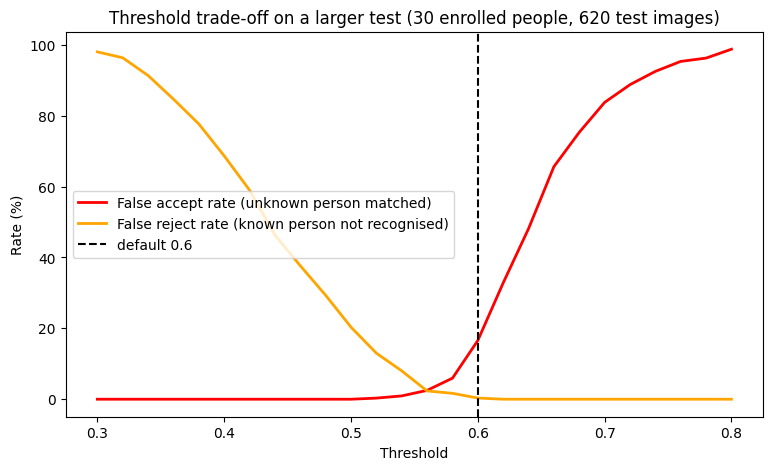

In [17]:
Qb = np.array(Qb_enc)
Kb = np.array(Kb_enc)
actual_b = np.array(Kb_actual)
TOTAL_B = len(actual_b) + no_face_b
n_known_t = int((actual_b != "unknown").sum())
n_unk_t = int((actual_b == "unknown").sum())

dist_b = np.linalg.norm(Kb[:, None, :] - Qb[None, :, :], axis=2)
best_b = dist_b.argmin(axis=1)
best_db = dist_b.min(axis=1)

def predict_big(th):
    return np.array([Qb_names[b] if bd <= th else "unknown" for b, bd in zip(best_b, best_db)])

def report_big(th):
    p = predict_big(th)
    correct = (p == actual_b).sum()
    fa = ((p != "unknown") & (actual_b == "unknown")).sum()                          # unknown person was matched
    fr = ((p == "unknown") & (actual_b != "unknown")).sum()                          # known person was not recognised
    wp = ((p != "unknown") & (actual_b != "unknown") & (p != actual_b)).sum()        # known person labelled as another known person
    print(f"\n===== Larger test, threshold {th} =====")
    print(f"Enrolled people : {len(Qb_names)}")
    print(f"Test images     : {TOTAL_B} ({n_known_t} of known people, {n_unk_t} of unknown people)")
    print(f"Accuracy        : {correct}/{TOTAL_B} = {correct / TOTAL_B * 100:.1f}%")
    print(f"False accepts   : {fa}")
    print(f"False rejects   : {fr}")
    print(f"Wrong person    : {wp}")
    print(f"No face found   : {no_face_b}")

report_big(0.6)
report_big(0.5)

# What changes when the threshold changes (rates, so the two curves are comparable)
ths = np.arange(0.30, 0.81, 0.02)
far, frr = [], []
for th in ths:
    p = predict_big(th)
    far.append(((p != "unknown") & (actual_b == "unknown")).sum() / n_unk_t * 100)
    frr.append(((p == "unknown") & (actual_b != "unknown")).sum() / n_known_t * 100)

cross = int(np.argmin(np.abs(np.array(far) - np.array(frr))))
print(f"\nThe two error rates are closest at threshold ~{ths[cross]:.2f} "
      f"(false accept {far[cross]:.1f}%, false reject {frr[cross]:.1f}%)")

plt.figure(figsize=(9, 5))
plt.plot(ths, far, color="red", linewidth=2, label="False accept rate (unknown person matched)")
plt.plot(ths, frr, color="orange", linewidth=2, label="False reject rate (known person not recognised)")
plt.axvline(0.6, color="black", linestyle="--", label="default 0.6")
plt.xlabel("Threshold")
plt.ylabel("Rate (%)")
plt.title(f"Threshold trade-off on a larger test ({len(Qb_names)} enrolled people, {TOTAL_B} test images)")
plt.legend()
plt.show()

In [18]:
report_big(0.56)


===== Larger test, threshold 0.56 =====
Enrolled people : 30
Test images     : 620 (300 of known people, 320 of unknown people)
Accuracy        : 603/620 = 97.3%
False accepts   : 8
False rejects   : 7
Wrong person    : 2
No face found   : 0
